# EEG VAE Validation Module - Feature Distribution Comparison

This notebook is designed to quantitatively assess how realistically our VAE-generated EEG data reflects the distribution of real EEG signals.

We achieve this comparison using an adapted version of the Fréchet Inception Distance (FID), which compares distributions in a high-dimensional embedding space. This embedding space is derived from a specialized EEG feature extractor, which is a pre-trained neural network model.

In [1]:
# Importing Libraries

import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset
from scipy.linalg import sqrtm
from sklearn.metrics import pairwise_distances
import torch.nn.functional as F

# Library imports - use centralized implementations for data loading
from generative_eeg_augmentation.data.loader import load_all_preprocessed

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [2]:
# Load preprocessed EEG data using library's data loader
# This replaces the old Windows-specific path loading with portable library function

real_epochs, labels = load_all_preprocessed()
real_data = torch.tensor(real_epochs, dtype=torch.float32).to(device)

# Sampling frequency is 200 Hz (downsampled during preprocessing)
sfreq = 200

print(f"Loaded {len(real_epochs)} epochs from preprocessed dataset")
print(f"Data shape: {real_data.shape} (epochs, channels, timepoints)")
print(f"Sampling frequency: {sfreq} Hz")

Loaded preprocessed EEG data shape: (250, 63, 1001)
Loaded labels shape: (250, 2)
Loaded 250 epochs from preprocessed dataset
Data shape: torch.Size([250, 63, 1001]) (epochs, channels, timepoints)
Sampling frequency: 200 Hz


In [3]:
# Define the Variational Autoencoder Model (VAE)
# NOTE: This VAE uses a LINEAR encoder architecture, which differs from the library's 
# VAE (Conv1d encoder) in generative_eeg_augmentation.models.vae. This architecture
# was used for the original FID evaluation and is kept for consistency with stored results.

class VAE(nn.Module):
    def __init__(self, n_channels=63, latent_dim=100, target_signal_len=1001):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_channels * target_signal_len, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim) 
        )
        self.fc_mu = nn.Linear(latent_dim, latent_dim)
        self.fc_logvar = nn.Linear(latent_dim, latent_dim)
        self.decoder_input = nn.Linear(latent_dim, 256 * (target_signal_len // 8))
        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose1d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose1d(64, n_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def encode(self, x):
        x = self.encoder(x.view(x.size(0), -1))
        mu, logvar = self.fc_mu(x), self.fc_logvar(x)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        x = self.decoder_input(z)
        x = x.view(x.size(0), 256, -1)
        return self.decoder(x)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

In [4]:
# Initialize VAE model
# NOTE: No pre-trained weights are loaded - the VAE is initialized randomly
# for demonstrating the FID evaluation pipeline. To use a trained VAE,
# load weights using: vae_model.load_state_dict(torch.load('path/to/weights.pth'))

vae_model = VAE(n_channels=63, latent_dim=100, target_signal_len=1001)
vae_model = vae_model.to(device)
vae_model.eval()

print("VAE model initialized (randomly initialized weights).")

VAE model initialized (randomly initialized weights).


In [5]:
# Generate Synthetic EEG Data using VAE
def generate_synthetic_data(vae_model, num_samples=100, latent_dim=100, device="cpu"):
    z = torch.randn(num_samples, latent_dim).to(device)
    with torch.no_grad():
        synthetic_data = vae_model.decode(z)
    
    return synthetic_data.cpu().numpy()

### EEG Feature Extractor

In [6]:
class FeatureExtractor(nn.Module):
    def __init__(self):
        super(FeatureExtractor, self).__init__()
        self.extractor = nn.Sequential(
            nn.Conv1d(63, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 64)
        )

    def forward(self, x):
        return self.extractor(x)


feature_extractor = FeatureExtractor().to(device)
print("EEG feature extractor loaded successfully.")

EEG feature extractor loaded successfully.


### Compute FID (Fréchet Inception Distance) Score

The FID score helps measure how realistic synthetic EEG signals are by comparing them to real EEG data.                                                
Lower Score = Better Match.

In [7]:
def compute_fid(real_features, synthetic_features):
    """
    Compute Fréchet Inception Distance between real and synthetic features.
    
    Lower FID scores indicate better match between distributions.
    """
    # Calculate the mean and covariance of both real and synthetic feature sets
    mu_real, sigma_real = np.mean(real_features, axis=0), np.cov(real_features, rowvar=False)
    mu_syn, sigma_syn = np.mean(synthetic_features, axis=0), np.cov(synthetic_features, rowvar=False)
    
    # Compute the FID score
    diff = mu_real - mu_syn
    covmean = sqrtm(sigma_real.dot(sigma_syn))
    
    # Handle potential numerical issues with sqrtm
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    
    fid = np.sum(diff**2) + np.trace(sigma_real + sigma_syn - 2 * covmean)
    return fid

### Visualizations

FID Score: 0.0163


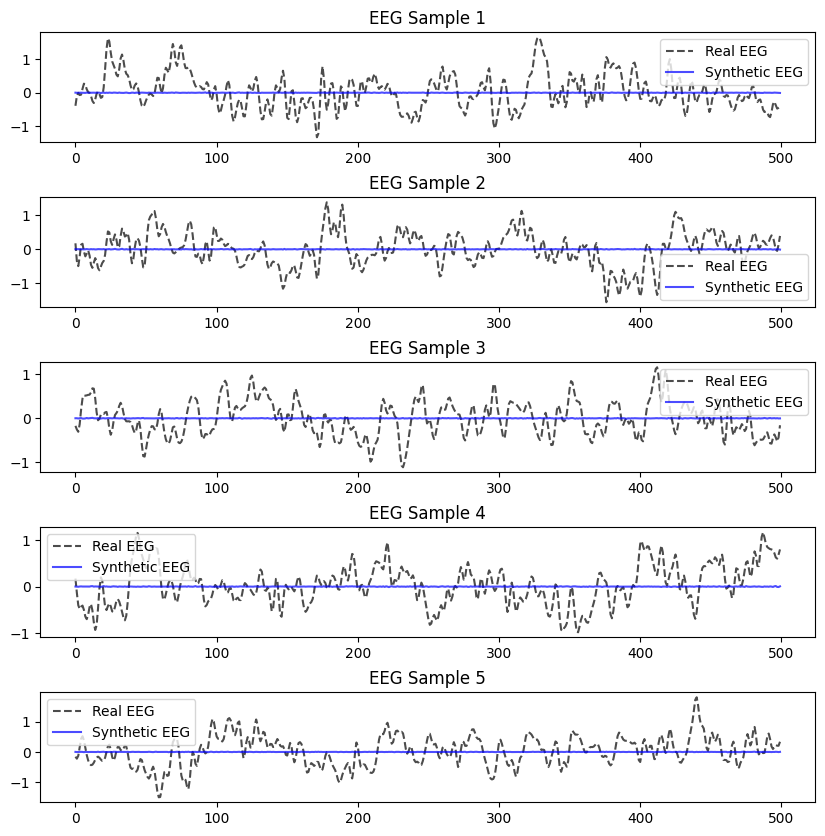

In [8]:
def plot_merged_eeg(real_data, synthetic_data, n_samples=5, time_points=500):
    """Plot merged real vs synthetic EEG comparison."""
    plt.figure(figsize=(10, 2 * n_samples))

    for i in range(n_samples):
        plt.subplot(n_samples, 1, i + 1)

        # Select the first time_points for plotting
        real_sample = real_data[i, :, :time_points].mean(axis=0)
        synthetic_sample = synthetic_data[i, :, :time_points].mean(axis=0)

        plt.plot(real_sample, label="Real EEG", color='black', linestyle='dashed', alpha=0.7)
        plt.plot(synthetic_sample, label="Synthetic EEG", color='blue', alpha=0.7)

        plt.title(f"EEG Sample {i+1}")
        plt.legend()

    plt.subplots_adjust(hspace=0.5)
    plt.show()

# Generate synthetic data for evaluation
num_samples = min(len(real_data), 100)
latent_dim = 100
synthetic_data = generate_synthetic_data(vae_model, num_samples=num_samples, latent_dim=latent_dim, device=device)

# Use real data from library loader (already on device)
real_data_subset = real_data[:num_samples]

# Extract features for FID computation
real_features = feature_extractor(real_data_subset).cpu().detach().numpy()
synthetic_features = feature_extractor(torch.tensor(synthetic_data, dtype=torch.float32).to(device)).cpu().detach().numpy()

# Compute FID score
fid_score = compute_fid(real_features, synthetic_features)
print(f"FID Score: {fid_score:.4f}")

# Visualize merged real vs. synthetic EEG
plot_merged_eeg(real_data_subset.cpu().numpy(), synthetic_data, n_samples=5, time_points=500)

### We are visualizing and comparing real EEG signals (dashed black) with synthetic EEG signals (solid blue) generated by a Variational Autoencoder (VAE). The goal is to see if the synthetic EEG preserves the key characteristics of real EEG.

### Each subplot represents an EEG sample, with real and synthetic signals plotted together. This allows us to assess how well the synthetic EEG mimics the real EEG in terms of structure, noise, and overall waveform dynamics.